# Application to field data over the Registro do Araguaia anomaly

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [5]:
import pickle

In [6]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [7]:
import gc

In [8]:
from tqdm import trange, tqdm

In [9]:
from scipy import optimize as op

In [10]:
import geopandas as gpd

In [11]:
from shapely.geometry import Point

In [12]:
def signed_center_mass(data, x, y):
    
    # Define masks for positive and negative data values
    positive = (data > 0.)
    negative = (data < 0.)
    
    # Compute the center of mass of the positive data
    x0_positive = (
        np.sum(data[positive]*x[positive]) / 
        np.sum(data[positive])
    )
    y0_positive = (
        np.sum(data[positive]*y[positive]) / 
        np.sum(data[positive])
    )
    
    # Compute the center of mass of the negative data
    x0_negative = (
        np.sum(data[negative]*x[negative]) / 
        np.sum(data[negative])
    )
    y0_negative = (
        np.sum(data[negative]*y[negative]) / 
        np.sum(data[negative])
    )
    
    # Compute the signed center of mass
    x0 = (x0_positive + x0_negative) / 2
    y0 = (y0_positive + y0_negative) / 2

    return x0, y0

In [13]:
def fill_nan_with_neighbor_mean_numpy(arr, max_iter=10, verbose=True):
    """
    Fill np.nan values in a 2D numpy array by the mean of adjacent neighbors
    (including diagonals). Repeat until no NaNs remain or max_iter is reached.
    NumPy-only implementation with verbose logging.
    
    Parameters:
    - arr: 2D numpy array with float values and np.nan.
    - max_iter: Maximum number of iterations.
    - verbose: If True, prints detailed logs each iteration.
    
    Returns:
    - Filled 2D numpy array.
    """
    filled = arr.copy()
    rows, cols = filled.shape

    # Define shifts: 8 directions (diagonal + cardinal)
    shifts = [(-1, -1), (-1, 0), (-1, 1),
              ( 0, -1),          ( 0, 1),
              ( 1, -1), ( 1, 0), ( 1, 1)]

    for iteration in range(max_iter):
        nan_mask = np.isnan(filled)
        if not np.any(nan_mask):
            if verbose:
                print(f"[Iteration {iteration}] All NaNs filled. Stopping.")
            break

        neighbor_sum = np.zeros_like(filled)
        neighbor_count = np.zeros_like(filled, dtype=int)

        for dx, dy in shifts:
            shifted = np.full_like(filled, np.nan)
            
            # Compute valid slicing indices for shifting
            x_src_start = max(0, -dx)
            x_src_end   = rows - max(0, dx)
            x_dst_start = max(0, dx)
            x_dst_end   = rows - max(0, -dx)

            y_src_start = max(0, -dy)
            y_src_end   = cols - max(0, dy)
            y_dst_start = max(0, dy)
            y_dst_end   = cols - max(0, -dy)
            
            # Copy shifted values
            shifted[x_dst_start:x_dst_end, y_dst_start:y_dst_end] = \
                filled[x_src_start:x_src_end, y_src_start:y_src_end]

            # Add to sum where not NaN
            valid_mask = ~np.isnan(shifted)
            neighbor_sum += np.where(valid_mask, shifted, 0)
            neighbor_count += valid_mask.astype(int)

        # Compute mean safely
        neighbor_mean = np.divide(
            neighbor_sum, 
            neighbor_count, 
            out=np.zeros_like(neighbor_sum), 
            where=neighbor_count != 0
        )

        # New values to be filled
        new_values = neighbor_mean[nan_mask]

        # Logging
        if verbose:
            n_to_fill = np.sum(nan_mask)
            mean_new_values = np.mean(new_values) if new_values.size > 0 else np.nan
            print(f"[Iteration {iteration}] NaNs to fill: {n_to_fill}, "
                  f"Mean of new fill values: {mean_new_values:.4f}")

        # Check if something changed
        prev_values = filled[nan_mask]
        if np.allclose(new_values, prev_values, equal_nan=True):
            if verbose:
                print(f"[Iteration {iteration}] No change detected. Stopping.")
            break

        filled[nan_mask] = new_values

    return filled

In [14]:
def data_statistics(data, name):
    print(f'{name}:')
    print(f"min    = {np.min(data):>7.2f} m")
    print(f"mean   = {np.mean(data):>7.2f} m")
    print(f"stdev  = {np.std(data):>7.2f} m")
    print(f"median = {np.median(data):>7.2f} m")
    print(f"max    = {np.max(data):>7.2f} m")

### Set path for saving figures

In [15]:
figures = '../manuscript/figures/'

## Load continent/country outlines

In [16]:
countries = gpd.read_file("../field_data/countries/ne_110m_admin_0_countries_lakes.shp")

## Load the raw data

In [17]:
with open('../field_data/araguaia.pickle', 'rb') as file:
    data = pickle.load(file)
# with open('../field_data/dados.dat', 'rb') as file:
#     data = np.loadtxt('../field_data/dados.dat', skiprows=1)

In [18]:
coordinates = {
    'x' : data['Y'],
    'y' : data['X'],
    'z' : -data['Z']
}

In [19]:
tfa = data['TFA']

In [20]:
terrain = -data['MDT']

In [21]:
latitude = data['LAT']
longitude = data['LONG']

In [22]:
print(f"Center of the study area:\n Latitude  {latitude.mean():>.2f}° \n Longitude {longitude.mean():>.2f}°")

Center of the study area:
 Latitude  -15.80° 
 Longitude -51.62°


In [23]:
study_area = gpd.GeoDataFrame(
    [(data['LONG'].mean(), data['LAT'].mean()),], 
    geometry=[Point(data['LONG'].mean(), data['LAT'].mean()),], 
    crs="EPSG:4326" # WGS 84
)

In [24]:
del data
gc.collect()

0

In [25]:
print(f"Total number of data points: {tfa.size}")

Total number of data points: 480830


In [26]:
data_statistics(terrain, 'Digital terrain model')

Digital terrain model:
min    = -500.00 m
mean   = -318.21 m
stdev  =   30.65 m
median = -314.52 m
max    = -249.99 m


In [27]:
data_statistics(coordinates['z'], 'Vertical coordinates')

Vertical coordinates:
min    = -616.60 m
mean   = -426.43 m
stdev  =   30.53 m
median = -422.62 m
max    = -358.41 m


In [28]:
ranges_terrain = [terrain.min(), terrain.max()]
ranges_tfa = [-np.max(np.abs(tfa)), np.max(np.abs(tfa))]

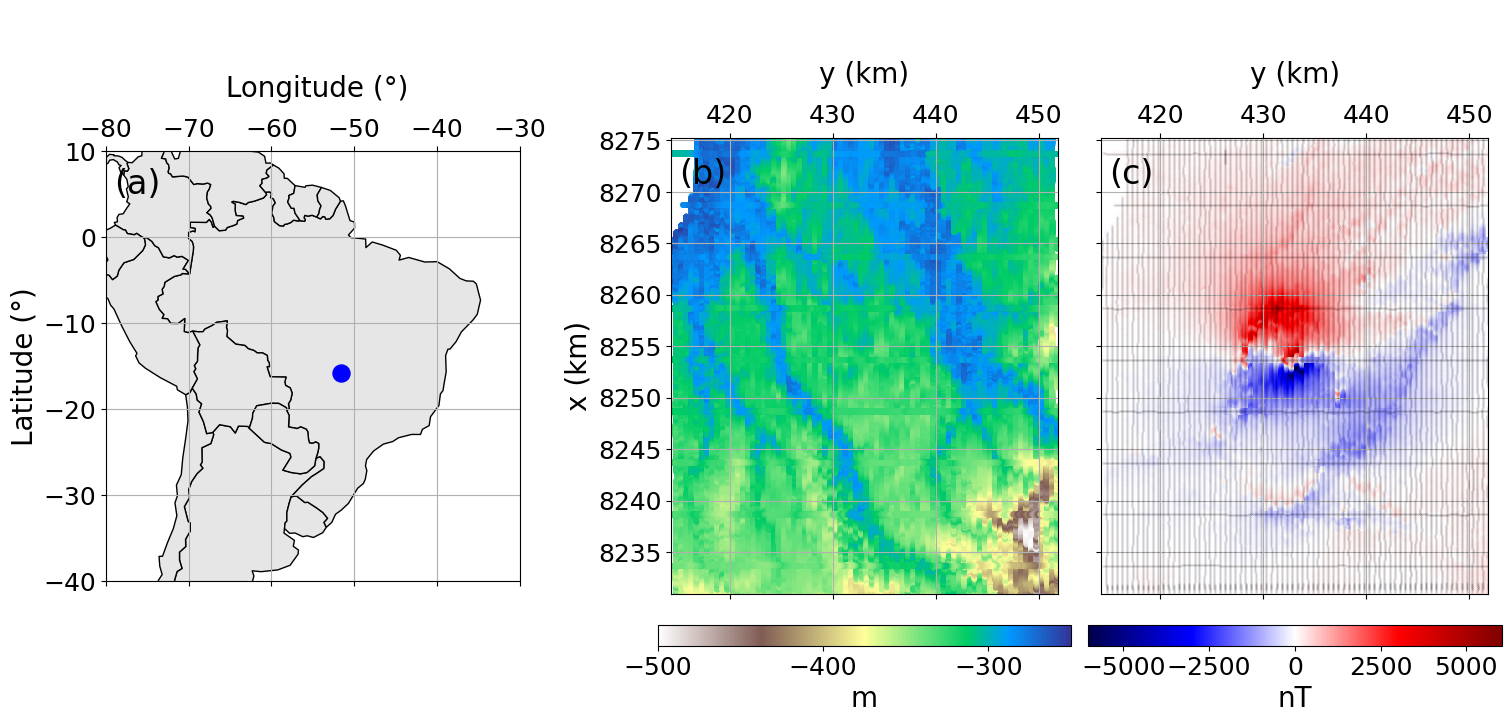

In [29]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,7)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=False, sharey=False
)

# Plot Brazil
ax = mosaic['a']
ax.axis('scaled')
# Plot countries
countries.plot(ax=ax, color=3*(0.9,), edgecolor='black')
study_area.plot(
    ax=ax, color='blue', 
    alpha=1, 
    markersize=150,
    label = 'Study area'
)
ax.set_xlim(-80, -30)
ax.set_ylim(-40, 10)
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.grid()
ax.annotate('(a)', xy=(0.02, 0.90), xycoords='axes fraction', fontsize=24)

# Vertical coordinate of data
ax = mosaic['b']
ax.axis('scaled')
im = ax.scatter(
    x=1e-3*coordinates['y'],
    y=1e-3*coordinates['x'],
    s=10,
    c=terrain,
    cmap='terrain_r', vmin=ranges_terrain[0], vmax=ranges_terrain[1]
)
cb = fig.colorbar(
    im, 
    ax=ax, 
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('m', fontsize=20, loc='center')
ax.set_ylim(0.001*np.min(coordinates['x']), 0.001*np.max(coordinates['x']))
ax.set_xlim(0.001*np.min(coordinates['y']), 0.001*np.max(coordinates['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.grid()
ax.annotate('(b)', xy=(0.02, 0.90), xycoords='axes fraction', fontsize=24)

# Total-field anomaly data

ax = mosaic['c']
# ax.sharex(mosaic['b'])
# ax.sharey(mosaic['b'])
ax.axis('scaled')
im = ax.scatter(
    x=1e-3*coordinates['y'],
    y=1e-3*coordinates['x'],
    s=10, c=tfa,
    cmap='seismic', vmin=ranges_tfa[0], vmax=ranges_tfa[1]
)
cb = fig.colorbar(
    im, 
    ax=ax, 
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('nT', fontsize=20, loc='center')

pts = ax.plot(
    1e-3*coordinates['y'],
    1e-3*coordinates['x'],
    'k.', ms=0.1, alpha=0.1
)

ax.set_ylim(0.001*np.min(coordinates['x']), 0.001*np.max(coordinates['x']))
ax.set_xlim(0.001*np.min(coordinates['y']), 0.001*np.max(coordinates['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelleft=False)
ax.grid()
ax.annotate('(c)', xy=(0.02, 0.90), xycoords='axes fraction', fontsize=24)
    
element = 'a'
mosaic[element].set_ylabel("Latitude (°)", fontsize=20)
mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
mosaic[element].set_xlabel("\n\n Longitude (°)", fontsize=20, loc='center', labelpad=15)
mosaic[element].xaxis.set_label_position('top')

element = 'b'
mosaic[element].set_ylabel('x (km)', fontsize=20)

for element in ['b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')

plt.savefig(figures+'Figure8.png', dpi=300)

plt.show()

In [30]:
area_reduced = [
    np.min(coordinates['x']), 
    np.max(coordinates['x']),
    np.min(coordinates['y']), 
    np.max(coordinates['y'])
]
shape_reduced = (150, 80)

In [31]:
dx_reduced, dy_reduced = data_structures.grid_xy_spacing(area=area_reduced, shape=shape_reduced)
print('Grid spacing:')
print(f'dx = {dx_reduced:>.2f} m | dy = {dy_reduced:>.2f} m | n. data = {np.prod(shape_reduced)}')

Grid spacing:
dx = 297.64 m | dy = 475.41 m | n. data = 12000


In [32]:
spacing_reduced = (dx_reduced, dy_reduced)

In [33]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x=np.linspace(area_reduced[0] + dx_reduced/2, area_reduced[1] - dx_reduced/2, shape_reduced[0]),
    y=np.linspace(area_reduced[2] + dy_reduced/2, area_reduced[3] - dy_reduced/2, shape_reduced[1]),
    shape=shape_reduced
)

In [34]:
# insert the X and Y coordinates 
coordinates_reduced = dict()
coordinates_reduced['x'] = X
coordinates_reduced['y'] = Y

In [35]:
del X, Y
gc.collect()

33

In [36]:
blocks_indices = utils.block_data(
    x=coordinates['x'],
    y=coordinates['y'],
    area=area_reduced,
    shape=shape_reduced
)

In [37]:
coordinates_reduced['z'] = utils.reduce_data(
    data=coordinates['z'],
    blocks_indices=blocks_indices,
    function='mean', 
    remove_nan=False
)

In [38]:
# Verify the output shape
coordinates_reduced['z'].shape

(150, 80)

In [39]:
# Verify that there is no nan
nan_values = np.isnan(coordinates_reduced['z'])
nan_values.any()

True

In [40]:
# number of blocks without data points
coordinates_reduced['z'][nan_values].size

810

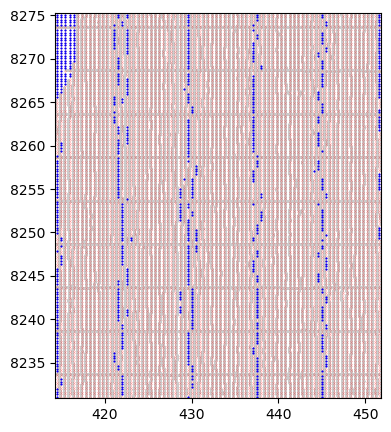

In [41]:
fig, ax = plt.subplots(figsize=(10,5))
ax.axis('scaled')

ax.scatter(
    x=1e-3*coordinates['y'], 
    y=1e-3*coordinates['x'], 
    s=0.3, marker='.', color=3*(0.8,)
)

ax.scatter(
    x=1e-3*coordinates_reduced['y'], 
    y=1e-3*coordinates_reduced['x'], 
    s=0.1, marker='.', color='r'
)

ax.scatter(
    x=1e-3*coordinates_reduced['y'][np.isnan(coordinates_reduced['z'])].ravel(), 
    y=1e-3*coordinates_reduced['x'][np.isnan(coordinates_reduced['z'])].ravel(), 
    s=0.3, marker='x', color='b'
)

ax.set_xlim(1e-3 * area_reduced[2], 1e-3 * area_reduced[3])
ax.set_ylim(1e-3 * area_reduced[0], 1e-3 * area_reduced[1])

plt.show()

In [42]:
# Fill nan values with the mean of its non-nan neighbors
coordinates_reduced['z'] = fill_nan_with_neighbor_mean_numpy(
    coordinates_reduced['z'], 
    verbose=True
)

[Iteration 0] NaNs to fill: 810, Mean of new fill values: -380.3002
[Iteration 1] All NaNs filled. Stopping.


In [43]:
# Verify that there is no nan
nan_values = np.isnan(coordinates_reduced['z'])
nan_values.any()

False

In [44]:
# number of blocks without data points
coordinates_reduced['z'][nan_values].size

0

In [45]:
data_statistics(coordinates['z'], 'Original vertical coordinates')
data_statistics(coordinates_reduced['z'], 'Reduced vertical coordinates')

Original vertical coordinates:
min    = -616.60 m
mean   = -426.43 m
stdev  =   30.53 m
median = -422.62 m
max    = -358.41 m
Reduced vertical coordinates:
min    = -615.67 m
mean   = -422.65 m
stdev  =   45.66 m
median = -422.01 m
max    =    0.00 m


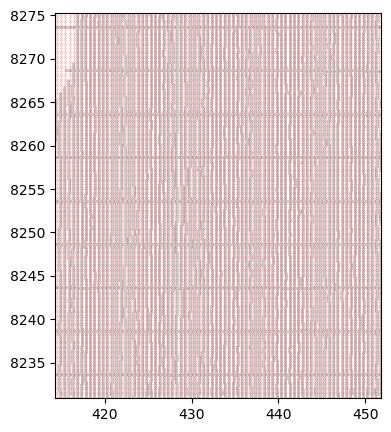

In [46]:
fig, ax = plt.subplots(figsize=(10,5))
ax.axis('scaled')

ax.scatter(
    x=1e-3*coordinates['y'], 
    y=1e-3*coordinates['x'], 
    s=0.3, marker='.', color=3*(0.8,)
)

ax.scatter(
    x=1e-3*coordinates_reduced['y'], 
    y=1e-3*coordinates_reduced['x'], 
    s=0.1, marker='.', color='r'
)

ax.scatter(
    x=1e-3*coordinates_reduced['y'][np.isnan(coordinates_reduced['z'])].ravel(), 
    y=1e-3*coordinates_reduced['x'][np.isnan(coordinates_reduced['z'])].ravel(), 
    s=0.3, marker='x', color='b'
)

ax.set_xlim(1e-3 * area_reduced[2], 1e-3 * area_reduced[3])
ax.set_ylim(1e-3 * area_reduced[0], 1e-3 * area_reduced[1])

plt.show()

In [47]:
del coordinates
gc.collect()

3380

In [48]:
# Block-reduce the total-field anomaly data 
# and fill nan values with the mean of its neighbors
tfa_reduced = dict()

tfa_reduced = utils.reduce_data(
    data=tfa,
    blocks_indices=blocks_indices,
    function='mean',
    remove_nan=False
)
tfa_reduced = fill_nan_with_neighbor_mean_numpy(
    tfa_reduced, 
    verbose=True
)

[Iteration 0] NaNs to fill: 810, Mean of new fill values: 27.6132
[Iteration 1] All NaNs filled. Stopping.


In [49]:
data_statistics(tfa, 'Original total-field anomaly')
data_statistics(tfa_reduced, 'Reduced total-field anomaly')

Original total-field anomaly:
min    = -6032.36 m
mean   =   46.41 m
stdev  =  612.33 m
median =   24.96 m
max    = 5020.29 m
Reduced total-field anomaly:
min    = -5726.14 m
mean   =   49.61 m
stdev  =  609.95 m
median =   22.28 m
max    = 4748.97 m


In [50]:
# Block-reduce the terrain
# and fill nan values with the mean of its neighbors
terrain_reduced = dict()

terrain_reduced = utils.reduce_data(
    data=terrain,
    blocks_indices=blocks_indices,
    function='mean',
    remove_nan=False
)
terrain_reduced = fill_nan_with_neighbor_mean_numpy(
    terrain_reduced, 
    verbose=True
)

[Iteration 0] NaNs to fill: 810, Mean of new fill values: -283.5612
[Iteration 1] All NaNs filled. Stopping.


In [51]:
del tfa, terrain
gc.collect()

0

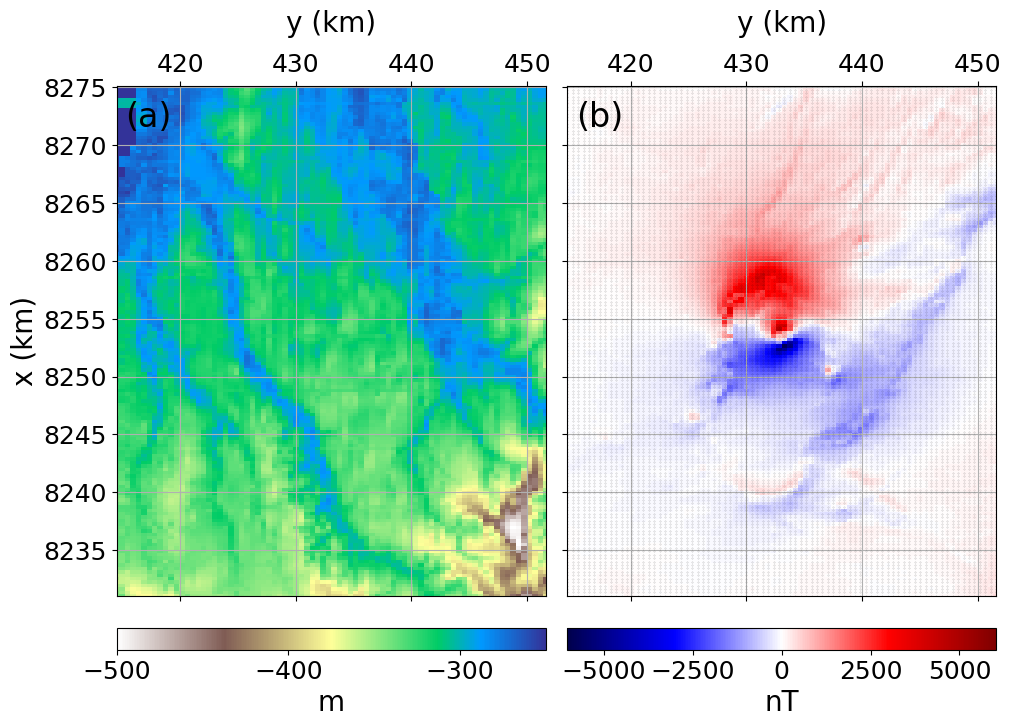

In [52]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(10,7)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             ab
             ''',
    sharex=True, sharey=True
)

# Vertical coordinate of data

ax = mosaic['a']
ax.axis('scaled')
# im = ax.scatter(
#     x=1e-3*coordinates['y'],
#     y=1e-3*coordinates['x'],
#     s=10,
#     c=terrain,
#     cmap='terrain_r', vmin=terrain.min(), vmax=terrain.max()
# )
im = ax.pcolormesh(
        coordinates_reduced['y']*0.001, coordinates_reduced['x']*0.001, 
        terrain_reduced,
        cmap='terrain_r', vmin=ranges_terrain[0], vmax=ranges_terrain[1]
    )
cb = fig.colorbar(
    im, 
    ax=ax, 
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('m', fontsize=20, loc='center')
ax.set_ylim(0.001*np.min(coordinates_reduced['x']), 0.001*np.max(coordinates_reduced['x']))
ax.set_xlim(0.001*np.min(coordinates_reduced['y']), 0.001*np.max(coordinates_reduced['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.grid()
ax.annotate('(a)', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)

# Total-field anomaly data

ax = mosaic['b']
ax.axis('scaled')
# im = ax.scatter(
#     x=1e-3*coordinates_reduced['y'],
#     y=1e-3*coordinates_reduced['x'],
#     s=10, c=tfa_reduced,
#     cmap='seismic', vmin=-ranges, vmax=ranges
# )
im = ax.pcolormesh(
        coordinates_reduced['y']*0.001, coordinates_reduced['x']*0.001, 
        tfa_reduced,
        cmap='seismic', vmin=ranges_tfa[0], vmax=ranges_tfa[1]
    )
cb = fig.colorbar(
    im, 
    ax=ax, 
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('nT', fontsize=20, loc='center')

pts = ax.plot(
    1e-3*coordinates_reduced['y'].T.ravel(),
    1e-3*coordinates_reduced['x'].T.ravel(),
    'k.', ms=0.5, alpha=0.3
)

ax.set_ylim(0.001*np.min(coordinates_reduced['x']), 0.001*np.max(coordinates_reduced['x']))
ax.set_xlim(0.001*np.min(coordinates_reduced['y']), 0.001*np.max(coordinates_reduced['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.grid()
ax.annotate('(b)', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')

plt.show()

In [53]:
# Set the equivalent layer depth
z_layer = np.median(coordinates_reduced['z']) + np.max(spacing_reduced)*1.5
print(f"Equivalent layer vertical coordinate at {z_layer:.2f} m")

Equivalent layer vertical coordinate at 291.10 m


In [54]:
# Rearrange the coordinates in a 'xy'-oriented flat array
for component in ['x', 'y', 'z']:
    coordinates_reduced[component] = coordinates_reduced[component].T.ravel()

In [55]:
# Rearrange data in a 'xy'-oriented flat array
tfa_reduced = tfa_reduced.T.ravel()

In [56]:
# compute the SEDM
R2 = inverse_distance.sedm(
    data_points = coordinates_reduced, 
    source_points = z_layer
)

In [57]:
# compute the gradient components
Grad = inverse_distance.grad(
    data_points = coordinates_reduced, 
    source_points = z_layer,
    SEDM = R2,
    components=['x', 'y', 'z']
)

In [58]:
# main field (IGRF) on August 15, 2004 (https://www.ngdc.noaa.gov/geomag/calculators/magcalc.shtml#igrfwmm)
F_hat = utils.unit_vector(inc=-18.4797, dec=-18.19)

In [59]:
# estimate the planar equivalent layer from Falcon data
rmse, layer = eqlayer.method_CGLS(
    sensitivity_matrices=[F_hat[0]*Grad['x'] + F_hat[1]*Grad['y'] + F_hat[2]*Grad['z']],
    data_vectors=[tfa_reduced],
    epsilon=1e-3,
    ITMAX=500
)

In [60]:
tfa_predicted = (F_hat[0]*Grad['x'] + F_hat[1]*Grad['y'] + F_hat[2]*Grad['z']) @ layer

In [61]:
# compute the amplitude of the anomalous magnetic field
bx_predicted = Grad['x'] @ layer
by_predicted = Grad['y'] @ layer
bz_predicted = Grad['z'] @ layer
b_predicted = np.sqrt(bx_predicted**2 + by_predicted**2 + bz_predicted**2)

In [62]:
del Grad, bx_predicted, by_predicted, bz_predicted
gc.collect()

17149

In [63]:
residuals = tfa_reduced - tfa_predicted

In [64]:
data_statistics(residuals, 'Residuals')

Residuals:
min    = -290.60 m
mean   =    0.06 m
stdev  =   14.45 m
median =    0.06 m
max    =  317.07 m


In [65]:
Q1 = np.quantile(residuals, 0.25)
Q3 = np.quantile(residuals, 0.75)
IQR = Q3 - Q1
print(f'Q1 = {Q1:>.2f} | Q3 = {Q3:>.2f} | IQR = {IQR:>.2f}')

Q1 = -3.55 | Q3 = 3.68 | IQR = 7.23


In [66]:
IQR_factor = 1.5
outliers = (residuals < Q1 - IQR_factor*IQR) | (residuals > Q3 + IQR_factor*IQR)

In [67]:
print(f"Outliers: {100*residuals[outliers].size/residuals.size:>.2f} %") 

Outliers: 11.28 %


In [68]:
# compute the total gradient of bz

Tensor = inverse_distance.grad_tensor(
    data_points = coordinates_reduced, 
    source_points = z_layer,
    SEDM = R2,
    components=['xz', 'yz', 'zz']
)

bxz_predicted = Tensor['xz'] @ layer
byz_predicted = Tensor['yz'] @ layer
bzz_predicted = Tensor['zz'] @ layer
grad_bz_predicted = np.sqrt(bxz_predicted**2 + byz_predicted**2 + bzz_predicted**2)
# grad_bz_predicted = np.sqrt(bxz_predicted**2 + byz_predicted**2)
del Tensor, bxz_predicted, byz_predicted, bzz_predicted
gc.collect()

0

In [69]:
# Rearrange the coordinates in a 2D array
for component in ['x', 'y', 'z']:
    coordinates_reduced[component] = data_structures.grid_xy_full_flatten_to_matrix(
        data=coordinates_reduced[component],
        grid_orientation='xy',
        shape=shape_reduced
    )

In [70]:
# Rearrange data in a 2D array
tfa_reduced = data_structures.grid_xy_full_flatten_to_matrix(
        data=tfa_reduced,
        grid_orientation='xy',
        shape=shape_reduced
    )

In [71]:
# Rearrange residuals in a 2D array
residuals = data_structures.grid_xy_full_flatten_to_matrix(
        data=residuals,
        grid_orientation='xy',
        shape=shape_reduced
    )

In [72]:
# Rearrange the layer in a 2D array
layer = data_structures.grid_xy_full_flatten_to_matrix(
        data=layer,
        grid_orientation='xy',
        shape=shape_reduced
    )

In [73]:
# Rearrange transformed field in a 2D array
grad_bz_predicted = data_structures.grid_xy_full_flatten_to_matrix(
        data=grad_bz_predicted,
        grid_orientation='xy',
        shape=shape_reduced
    )

In [74]:
# Rearrange transformed field in a 2D array
b_predicted = data_structures.grid_xy_full_flatten_to_matrix(
        data=b_predicted,
        grid_orientation='xy',
        shape=shape_reduced
    )

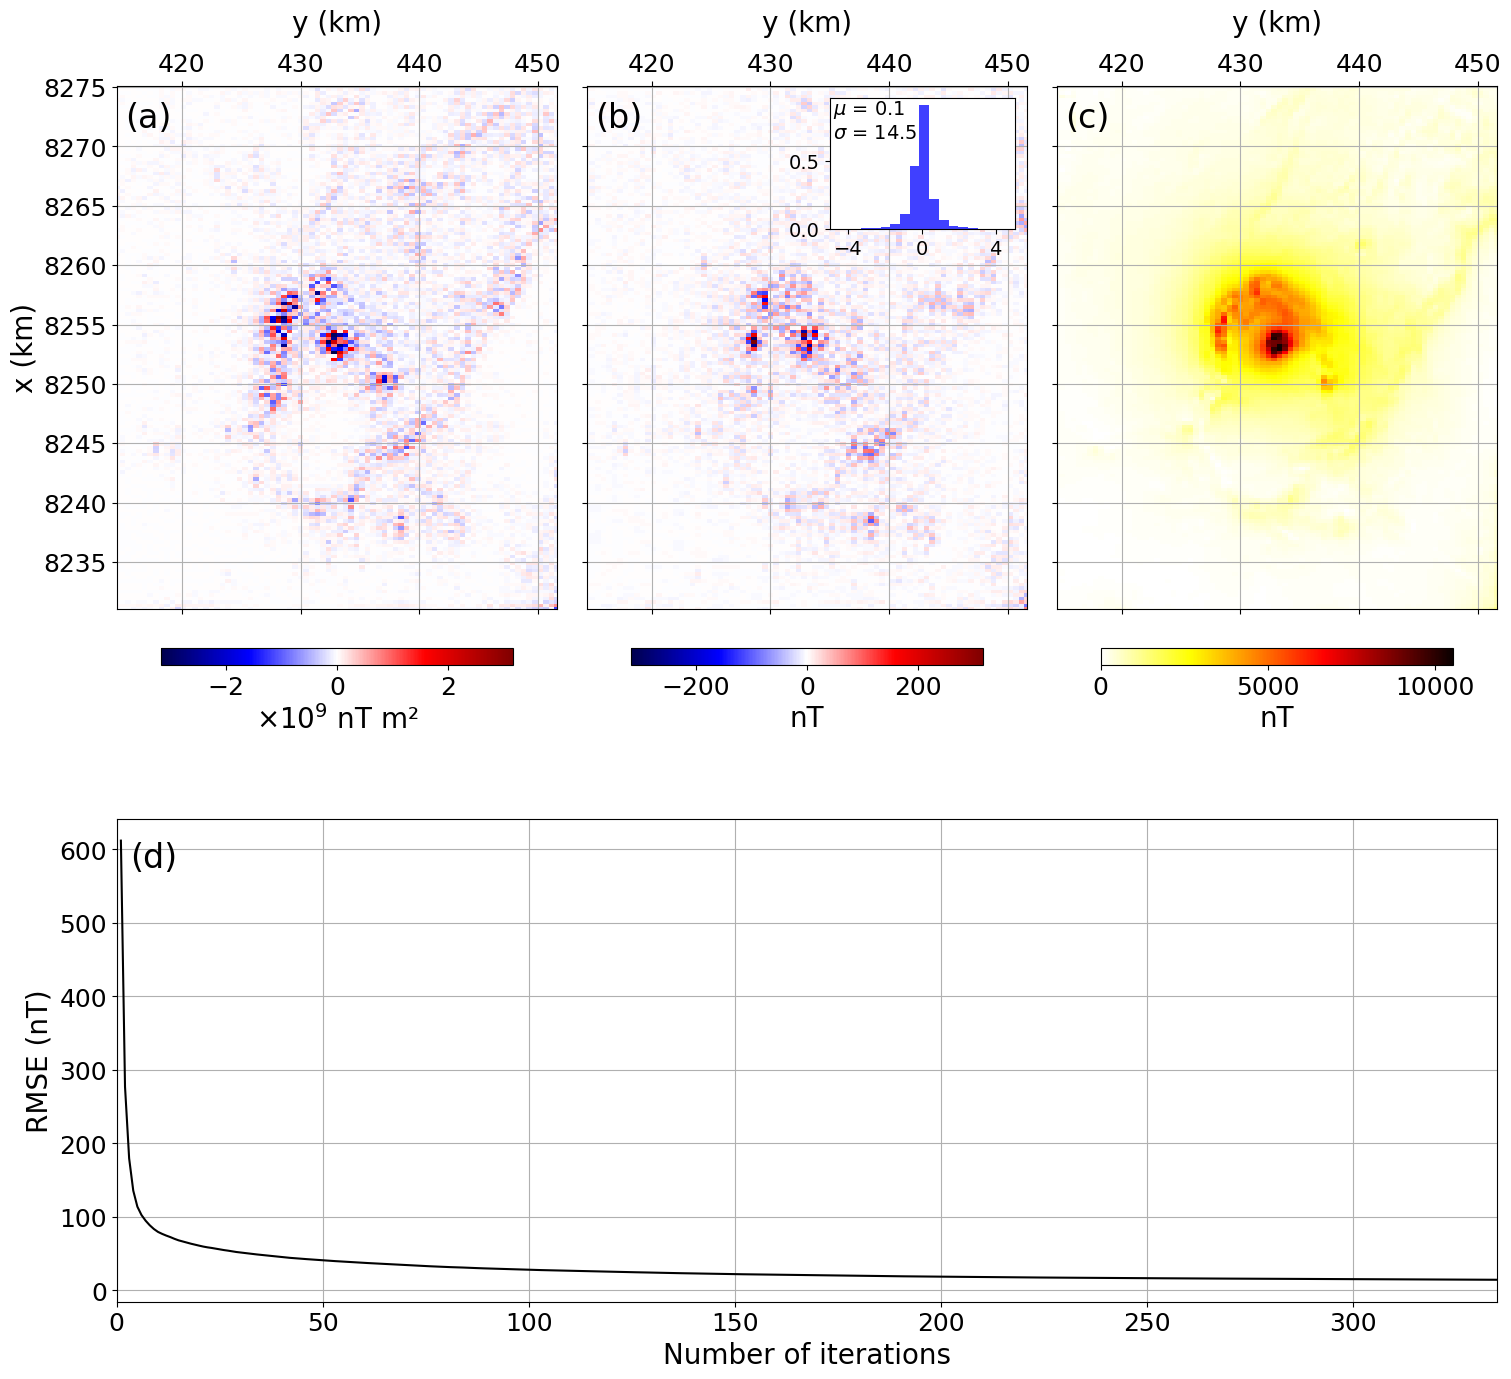

In [75]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,14)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ddd
             ''',
    sharex=False, sharey=False
)

# Estimated equivalent layer

ranges = np.max(np.abs(1e-9*layer))

ax = mosaic['a']
ax.axis('scaled')
im = ax.pcolormesh(
        coordinates_reduced['y']*0.001, coordinates_reduced['x']*0.001, 
        1e-9*layer,
        cmap='seismic', vmin=-ranges, vmax=ranges
    )
cb = fig.colorbar(
    im, 
    ax=ax, 
    shrink=0.8,
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('$\\times 10^{9}$ nT m²', fontsize=20, loc='center')

ax.set_ylim(0.001*np.min(coordinates_reduced['x']), 0.001*np.max(coordinates_reduced['x']))
ax.set_xlim(0.001*np.min(coordinates_reduced['y']), 0.001*np.max(coordinates_reduced['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.grid()
ax.annotate('(a)', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)


# Residuals

ranges = np.max(np.abs(residuals))

ax = mosaic['b']
ax.sharex(mosaic['a'])
ax.sharey(mosaic['a'])
ax.axis('scaled')
im = ax.pcolormesh(
        coordinates_reduced['y']*0.001, coordinates_reduced['x']*0.001, 
        residuals,
        cmap='seismic', vmin=-ranges, vmax=ranges
    )
cb = fig.colorbar(
    im, 
    ax=ax, 
    location='bottom',
    shrink=0.8,
    # extend='both'
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
cb.ax.set_xlabel('nT', fontsize=20, loc='center')

# pts = ax.plot(
#     1e-3*coordinates_reduced['y'].T.ravel(),
#     1e-3*coordinates_reduced['x'].T.ravel(),
#     'k.', ms=0.5, alpha=0.3
# )

ax.set_ylim(0.001*np.min(coordinates_reduced['x']), 0.001*np.max(coordinates_reduced['x']))
ax.set_xlim(0.001*np.min(coordinates_reduced['y']), 0.001*np.max(coordinates_reduced['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelleft=False)
ax.grid()
ax.annotate('(b)', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)

# the histogram of residuals
subax = inset_axes(ax, width="42%", height="25%", loc=1, borderpad=0.9)
mean = np.mean(residuals)
std = np.std(residuals)
res_norm = (residuals.T.ravel() - mean) / std
n, bins, patches = subax.hist(
    x=res_norm, bins=80, density=True, facecolor='blue', alpha=0.75
)
subax.xaxis.tick_bottom()
subax.yaxis.tick_left()
subax.set_xticks([-4.0,0.0,4.0])
subax.set_xlim(-5, 5)
subax.tick_params(axis='x', labelsize=14)
subax.tick_params(axis='y', labelsize=14)
subax.text(0.56, 0.90, "$\mu$ = {:.1f}\n$\sigma$ = {:.1f}".format(mean, std), transform = ax.transAxes, fontsize=14)

# Estimated total-gradient of the bz component

# ranges = np.max(np.abs(grad_bz_predicted))
ranges = np.max(b_predicted)

ax = mosaic['c']
ax.sharex(mosaic['a'])
ax.sharey(mosaic['a'])
ax.axis('scaled')
im = ax.pcolormesh(
        coordinates_reduced['y']*0.001, coordinates_reduced['x']*0.001, 
        # grad_bz_predicted,
        b_predicted,
        cmap='hot_r', vmin=0, vmax=ranges
        # cmap='hot_r', vmin=-ranges, vmax=ranges
    )
cb = fig.colorbar(
    im, 
    ax=ax, 
    shrink=0.8,
    location='bottom',
)
cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
# cb.ax.set_xlabel('nT/m', fontsize=20, loc='center')
cb.ax.set_xlabel('nT', fontsize=20, loc='center')

ax.set_ylim(0.001*np.min(coordinates_reduced['x']), 0.001*np.max(coordinates_reduced['x']))
ax.set_xlim(0.001*np.min(coordinates_reduced['y']), 0.001*np.max(coordinates_reduced['y']))
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelleft=False)
ax.grid()
ax.annotate('(c)', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)

    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')

# insert the convergence curve
ax = mosaic['d']
ax.set_box_aspect(0.35)
ax.plot([i+1 for i in range(len(rmse))], rmse, 'k-')
ax.annotate('(d)', xy=(0.01, 0.9), xycoords='axes fraction', fontsize=24)
ax.tick_params(labelsize=18)
ax.set_xlabel('Number of iterations', fontsize=20)
ax.set_ylabel('RMSE (nT)', fontsize=20)
ax.set_xlim(0,len(rmse))
ax.grid()

plt.savefig(figures+'Figure9.png', dpi=300)

plt.show()